# Sesión 06. Un mini GPT que aprende a hablar como telenovela

En esta sesión construimos, pieza por pieza, un modelo de lenguaje del mismo tipo que GPT: un **transformer decoder-only** que lee una secuencia de tokens y predice el siguiente. Lo entrenamos desde cero con los diálogos de *Teresa* (Televisa, 2010), una telenovela con ambición, celos, venganzas y frases memorables, ideal para ver cómo un modelo pasa de balbucear a imitar un estilo.

Ruta del cuaderno:

1. El corpus: subtítulos de los capítulos convertidos en diálogo plano.
2. Tokenización BPE: primero a mano sobre unas cuantas líneas, luego con SentencePiece.
3. De tokens a vectores: embeddings de token y de posición.
4. Atención con máscara causal, calculada a mano y comparada con PyTorch.
5. Multi-cabeza y el bloque transformer (LayerNorm, FFN, residuales).
6. Entrenamiento con entropía cruzada, AdamW, calentamiento y coseno.
7. Generación con temperatura, top-k y top-p.
8. Lo que aprendió: mapas de atención del modelo entrenado.

El cuaderno se genera con `scripts/build_minigpt_notebook.py`; si quieres cambiar una celda, cambia el script y regenera. La corrida larga (unos 10 minutos en la RTX 3070, hasta que la validación deja de mejorar) vive en `scripts/train_minigpt_teresa.py`; aquí entrenamos una versión corta para ver el proceso y luego cargamos el checkpoint largo.

In [1]:
import json
import math
import os
import random
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RAPIDO = os.environ.get("MINIGPT_RAPIDO", "1") == "1"


def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / "scripts" / "train_minigpt_teresa.py").exists():
            return parent
    for c in ["/workspace/friendly-fiesta", "/workspace"]:
        if (Path(c) / "notebooks").exists():
            return Path(c)
    return p


ROOT = find_repo_root()
CORPUS = ROOT / "data" / "raw" / "teresa" / "teresa.txt"
RUN = ROOT / "data" / "minigpt_run"
NB_RUN = RUN / "cuaderno"
NB_RUN.mkdir(parents=True, exist_ok=True)
if DEVICE.type == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.36)  # la GPU es compartida

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
NARANJA, PIZARRA = "#FF5900", "#262C34"
print("ROOT   =", ROOT)
print("torch  =", torch.__version__)
print("device =", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
print("modo rápido =", RAPIDO)

ROOT   = /workspace/friendly-fiesta
torch  = 2.14.1+cu130
device = cuda | NVIDIA GeForce RTX 3070 Laptop GPU
modo rápido = True


## 1. El corpus

`scripts/descargar_teresa.py` busca capítulos y escenas de *Teresa* en YouTube y baja **solo los subtítulos en español** (casi todos automáticos). Después los limpia: quita marcas de tiempo y etiquetas, elimina las repeticiones que produce el subtítulo automático (cada renglón aparece dos veces mientras se desplaza) y descarta anotaciones como `[Música]`. También descarta las escenas sueltas que repiten un capítulo ya incluido, para que la validación no contenga frases idénticas al entrenamiento.

El resultado es un archivo de texto plano, un renglón por fragmento de subtítulo, con los capítulos separados por una línea en blanco. En la mayoría de los capítulos el reconocimiento automático de voz de YouTube ya agrega puntuación, signos de interrogación y mayúsculas; en algunos falta la puntuación o se pierden letras acentuadas (aparece «dnde» en lugar de «dónde»), y en todos se equivoca con algunos nombres y corta los renglones a la mitad de una frase. El modelo aprenderá ese estilo con todo y sus defectos, porque un modelo de lenguaje imita la distribución de su corpus.

In [2]:
texto = CORPUS.read_text(encoding="utf-8")
capitulos = [c for c in texto.split("\n\n") if c.strip()]
lineas = [l for l in texto.splitlines() if l.strip()]
palabras = re.findall(r"\w+", texto.lower())
print(f"tamaño: {len(texto.encode()) / 1e6:.2f} MB | {len(texto):,} caracteres")
print(f"capítulos o escenas: {len(capitulos)} | renglones: {len(lineas):,} | palabras: {len(palabras):,}")
print(f"vocabulario de palabras distintas: {len(set(palabras)):,}")
print("\nUn fragmento al azar:\n")
i = random.Random(7).randrange(len(lineas) - 12)
print("\n".join(lineas[i:i + 12]))

tamaño: 2.52 MB | 2,458,276 caracteres
capítulos o escenas: 152 | renglones: 72,038 | palabras: 483,511
vocabulario de palabras distintas: 15,623

Un fragmento al azar:

meterse Usted bien sabe que mis papás se
fueron para el rancho no nos quedamos y
yo aquí solo sin dnde vivir Mira
Espérame aquí tantito s y luego
platicamos pero no te prometo nada eh No
no no Bueno aquí la espera Doña Gema
Qué pasó Johnny es broncas de
murió el chavo es el riquillo no Mentes
la verdad yo no sé ni de quién me hablas
ni creas que me traigo tu cara de
inocente tú le vendías tus porquerías y
por eso ese chavo se dio un pasón ya ves


teresa   aparece  3291 veces
mariano  aparece  1571 veces
arturo   aparece  2103 veces
aurora   aparece   615 veces


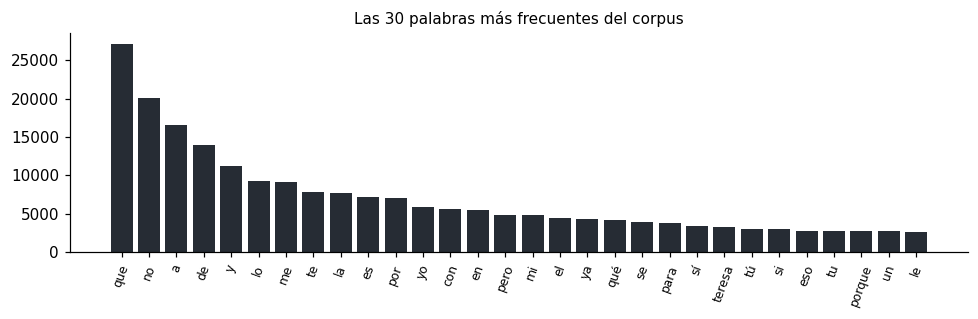

In [3]:
frec = Counter(palabras)
top = frec.most_common(30)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar([w for w, _ in top], [c for _, c in top], color=PIZARRA)
for nombre in ("teresa", "mariano", "arturo", "aurora"):
    print(f"{nombre:8s} aparece {frec[nombre]:5d} veces")
ax.set_title("Las 30 palabras más frecuentes del corpus")
ax.tick_params(axis="x", rotation=70, labelsize=8)
plt.tight_layout(); plt.show()

La ley de Zipf se ve de inmediato: unas pocas palabras (`que`, `no`, `de`, `a`, `me`) concentran gran parte del texto y miles de palabras aparecen una sola vez. Esa cola larga es la razón por la que no conviene un vocabulario de palabras completas: el modelo vería demasiadas palabras raras pocas veces. Tampoco conviene trabajar letra por letra, porque las secuencias serían larguísimas. La solución intermedia es la tokenización por subpalabras.

## 2. Tokenización BPE

**Byte-Pair Encoding** (BPE) construye el vocabulario de abajo hacia arriba:

1. Empieza con los caracteres. Cada palabra es una secuencia de letras; el espacio que la precede se marca con `▁`.
2. Cuenta todos los pares de símbolos adyacentes en el corpus.
3. Fusiona el par más frecuente en un símbolo nuevo y lo anota como una regla de fusión (*merge*).
4. Repite hasta llegar al tamaño de vocabulario deseado.

Para tokenizar una frase nueva se aplican las reglas en el mismo orden en que se aprendieron. Implementémoslo a mano sobre las primeras líneas del corpus.

In [4]:
def bpe_entrenar(lineas, n_fusiones):
    # Vocabulario de palabras: cada palabra como tupla de símbolos, con su frecuencia.
    vocab = Counter()
    for l in lineas:
        for w in l.lower().split():
            vocab[tuple("▁" + w)] += 1
    fusiones = []
    for _ in range(n_fusiones):
        pares = Counter()
        for simbolos, f in vocab.items():
            for a, b in zip(simbolos, simbolos[1:]):
                pares[(a, b)] += f
        if not pares:
            break
        (a, b), f = pares.most_common(1)[0]
        fusiones.append((a, b, f))
        nuevo = Counter()
        for simbolos, fr in vocab.items():
            s, i = [], 0
            while i < len(simbolos):
                if i < len(simbolos) - 1 and simbolos[i] == a and simbolos[i + 1] == b:
                    s.append(a + b); i += 2
                else:
                    s.append(simbolos[i]); i += 1
            nuevo[tuple(s)] += fr
        vocab = nuevo
    return fusiones


def bpe_aplicar(frase, fusiones, verbose=False):
    resultado = []
    for w in frase.lower().split():
        s = list("▁" + w)
        for a, b, _ in fusiones:
            i, cambio = 0, False
            while i < len(s) - 1:
                if s[i] == a and s[i + 1] == b:
                    s[i:i + 2] = [a + b]; cambio = True
                else:
                    i += 1
            if cambio and verbose:
                print(f"  fusión {a!r} + {b!r:8s} -> {' | '.join(s)}")
        resultado += s
    return resultado


t0 = time.time()
fusiones = bpe_entrenar(lineas[:20000], 300)
print(f"300 fusiones aprendidas en {time.time() - t0:.1f} s. Las primeras 20:")
for k, (a, b, f) in enumerate(fusiones[:20], 1):
    print(f"{k:3d}. {a!r:6s} + {b!r:6s} -> {a + b!r:9s} ({f:,} veces)")

300 fusiones aprendidas en 7.3 s. Las primeras 20:
  1. 'e'    + 's'    -> 'es'      (12,729 veces)
  2. '▁'    + 'a'    -> '▁a'      (12,276 veces)
  3. 'q'    + 'u'    -> 'qu'      (12,244 veces)
  4. 'e'    + 'r'    -> 'er'      (11,492 veces)
  5. '▁'    + 'p'    -> '▁p'      (11,256 veces)
  6. '▁'    + 'qu'   -> '▁qu'     (10,115 veces)
  7. '▁'    + 'm'    -> '▁m'      (9,952 veces)
  8. '▁'    + 't'    -> '▁t'      (9,915 veces)
  9. 'e'    + 'n'    -> 'en'      (9,142 veces)
 10. '▁'    + 'd'    -> '▁d'      (8,949 veces)
 11. '▁'    + 's'    -> '▁s'      (8,714 veces)
 12. '▁'    + 'l'    -> '▁l'      (7,975 veces)
 13. '▁qu'  + 'e'    -> '▁que'    (7,787 veces)
 14. '▁'    + 'n'    -> '▁n'      (7,719 veces)
 15. '▁'    + 'c'    -> '▁c'      (7,698 veces)
 16. 'a'    + 'r'    -> 'ar'      (7,400 veces)
 17. '▁'    + 'es'   -> '▁es'     (6,525 veces)
 18. 'o'    + 'r'    -> 'or'      (6,442 veces)
 19. '▁n'   + 'o'    -> '▁no'     (6,092 veces)
 20. '▁'    + 'y'    -> '▁y'   

In [5]:
frase = "Teresa, eres una ambiciosa"
print("Frase:", frase)
tokens = bpe_aplicar(frase, fusiones, verbose=True)
print("\nTokens finales:", tokens)

Frase: Teresa, eres una ambiciosa
  fusión 'e' + 's'      -> ▁ | t | e | r | es | a | ,
  fusión 'e' + 'r'      -> ▁ | t | er | es | a | ,
  fusión '▁' + 't'      -> ▁t | er | es | a | ,
  fusión 'er' + 'es'     -> ▁t | eres | a | ,
  fusión '▁t' + 'eres'   -> ▁teres | a | ,
  fusión 'a' + ','      -> ▁teres | a,
  fusión '▁teres' + 'a,'     -> ▁teresa,
  fusión 'e' + 's'      -> ▁ | e | r | es
  fusión 'e' + 'r'      -> ▁ | er | es
  fusión 'er' + 'es'     -> ▁ | eres
  fusión 'u' + 'n'      -> ▁ | un | a
  fusión '▁' + 'un'     -> ▁un | a
  fusión '▁un' + 'a'      -> ▁una
  fusión '▁' + 'a'      -> ▁a | m | b | i | c | i | o | s | a
  fusión 'o' + 's'      -> ▁a | m | b | i | c | i | os | a
  fusión 'c' + 'i'      -> ▁a | m | b | i | ci | os | a
  fusión '▁a' + 'm'      -> ▁am | b | i | ci | os | a
  fusión 'b' + 'i'      -> ▁am | bi | ci | os | a

Tokens finales: ['▁teresa,', '▁', 'eres', '▁una', '▁am', 'bi', 'ci', 'os', 'a']


Las primeras fusiones capturan pares muy frecuentes del español (por ejemplo `q` + `u` o `▁` + `d`), luego sílabas y al final palabras completas como `▁que` o `▁teresa`. Una palabra rara, como *ambiciosa*, queda partida en trozos conocidos: el modelo nunca se topa con una palabra fuera de vocabulario.

En la práctica usamos **SentencePiece**, que implementa BPE de forma eficiente, trata el espacio como un carácter más (`▁`) y permite reconstruir el texto original sin ambigüedad. El script largo entrenó un vocabulario de 4000 piezas; si existe lo cargamos, si no, lo entrenamos aquí.

In [6]:
import sentencepiece as spm

NL = "<nl>"
modelo_sp = RUN / "teresa_bpe.model"
if not modelo_sp.exists():
    (NB_RUN / "lineas.txt").write_text("\n".join(lineas), encoding="utf-8")
    spm.SentencePieceTrainer.train(input=str(NB_RUN / "lineas.txt"), model_prefix=str(RUN / "teresa_bpe"),
                                   vocab_size=4000, model_type="bpe", character_coverage=1.0,
                                   user_defined_symbols=[NL], pad_id=-1, unk_id=0, bos_id=1, eos_id=2, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file=str(modelo_sp))
V = sp.get_piece_size()


def codificar(t):
    return sp.encode(t.replace("\n", f" {NL} "))


def decodificar(ids):
    return re.sub(rf"\s*{NL}\s*", "\n", sp.decode(ids))


for f in ["Teresa eres una ambiciosa", "yo nunca me voy a casar contigo", "Arturo de la Barrera", "la vecindad"]:
    ids = codificar(f)
    print(f"{f!r}\n   piezas: {[sp.id_to_piece(i) for i in ids]}\n   ids:    {ids}")
print("\nvocabulario:", V, "piezas | las primeras fusiones:", [sp.id_to_piece(i) for i in range(4, 24)])

'Teresa eres una ambiciosa'
   piezas: ['▁Teresa', '▁eres', '▁una', '▁ambi', 'ci', 'osa']
   ids:    [102, 425, 145, 1959, 38, 548]
'yo nunca me voy a casar contigo'
   piezas: ['▁yo', '▁nunca', '▁me', '▁voy', '▁a', '▁casar', '▁contigo']
   ids:    [72, 451, 33, 146, 7, 558, 392]
'Arturo de la Barrera'
   piezas: ['▁Arturo', '▁de', '▁la', '▁Barrera']
   ids:    [162, 24, 47, 1121]
'la vecindad'
   piezas: ['▁la', '▁vecindad']
   ids:    [47, 805]

vocabulario: 4000 piezas | las primeras fusiones: ['ue', 'es', 'er', '▁a', '▁p', '▁q', '▁m', '▁d', '▁t', 'en', '▁que', '▁s', '▁c', 'ar', '▁l', 'no', 'or', '▁es', 'as', '▁no']


2,458,276 caracteres -> 730,211 tokens: 3.37 caracteres por token


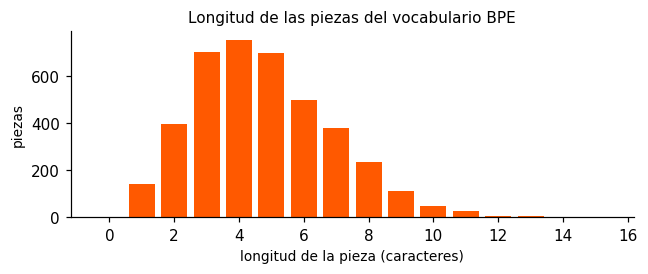

In [7]:
ids_todo = codificar(texto)
print(f"{len(texto):,} caracteres -> {len(ids_todo):,} tokens: {len(texto) / len(ids_todo):.2f} caracteres por token")
largos = Counter(len(sp.id_to_piece(i).replace('▁', '')) for i in range(V))
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(list(largos.keys()), list(largos.values()), color=NARANJA)
ax.set_xlabel("longitud de la pieza (caracteres)"); ax.set_ylabel("piezas")
ax.set_title("Longitud de las piezas del vocabulario BPE")
plt.tight_layout(); plt.show()

## 3. Pares de entrenamiento y embeddings

El modelo aprende una sola tarea: **predecir el siguiente token**. De una ventana de $T+1$ tokens consecutivos se obtiene la entrada $x = (t_1,\dots,t_T)$ y el objetivo $y = (t_2,\dots,t_{T+1})$, desplazado un lugar. En una sola ventana hay $T$ ejemplos: en cada posición el modelo debe adivinar lo que sigue usando solo lo anterior.

Separamos capítulos completos para validación (10 %), con la misma semilla que el script largo.

In [8]:
rng = random.Random(SEED)
orden = list(range(len(capitulos)))
rng.shuffle(orden)
val_idx = set(orden[:max(1, int(0.1 * len(capitulos)))])
nl_id = sp.piece_to_id(NL)
datos_tr = torch.tensor([t for i, c in enumerate(capitulos) if i not in val_idx for t in codificar(c) + [nl_id]])
datos_va = torch.tensor([t for i, c in enumerate(capitulos) if i in val_idx for t in codificar(c) + [nl_id]])
print(f"tokens de entrenamiento: {len(datos_tr):,} | validación: {len(datos_va):,}")

T_demo = 8
x_demo, y_demo = datos_tr[1000:1000 + T_demo], datos_tr[1001:1001 + T_demo]
for t in range(T_demo):
    contexto = " ".join(sp.id_to_piece(i) for i in x_demo[:t + 1].tolist())
    print(f"contexto: {contexto:60s} -> objetivo: {sp.id_to_piece(int(y_demo[t]))}")

tokens de entrenamiento: 663,225 | validación: 66,534
contexto: sión                                                         -> objetivo: ▁de
contexto: sión ▁de                                                     -> objetivo: ▁las
contexto: sión ▁de ▁las                                                -> objetivo: ▁
contexto: sión ▁de ▁las ▁                                              -> objetivo: <nl>
contexto: sión ▁de ▁las ▁ <nl>                                         -> objetivo: ▁ven
contexto: sión ▁de ▁las ▁ <nl> ▁ven                                    -> objetivo: as
contexto: sión ▁de ▁las ▁ <nl> ▁ven as                                 -> objetivo: ▁del
contexto: sión ▁de ▁las ▁ <nl> ▁ven as ▁del                            -> objetivo: ▁c


Cada token es un entero. La red lo convierte en un vector con una **tabla de embeddings** $W_E \in \mathbb{R}^{V\times d}$: el token $i$ toma la fila $i$. Como la atención no distingue el orden por sí sola, se suma un segundo vector que depende de la posición, tomado de otra tabla $W_P \in \mathbb{R}^{T_{\max}\times d}$:

$$h^{(0)}_t = W_E[x_t] + W_P[t].$$

Ambas tablas son parámetros que se aprenden con todo lo demás.

In [9]:
d = 384
W_E = nn.Embedding(V, d)
W_P = nn.Embedding(256, d)
x = x_demo.unsqueeze(0)                     # (B=1, T=8)
h0 = W_E(x) + W_P(torch.arange(x.size(1)))  # (1, 8, 384)
print("ids:", x.tolist())
print("forma de h0:", tuple(h0.shape), "| parámetros de W_E:", W_E.weight.numel(), "| de W_P:", W_P.weight.numel())

ids: [[1122, 24, 203, 3912, 3, 346, 22, 335]]
forma de h0: (1, 8, 384) | parámetros de W_E: 1536000 | de W_P: 98304


## 4. Atención con máscara causal

Cada posición produce tres vectores a partir de su representación $h_t$: una **consulta** $q_t = h_t W_Q$ (lo que busca), una **clave** $k_t = h_t W_K$ (lo que ofrece para ser encontrado) y un **valor** $v_t = h_t W_V$ (lo que entrega si la eligen). La afinidad entre la posición $t$ y la posición $s$ es el producto punto $q_t\cdot k_s$. En forma matricial:

$$\operatorname{Atención}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V,\qquad M_{ts} = \begin{cases}0 & s\le t\\ -\infty & s>t\end{cases}$$

La máscara $M$ impide mirar al futuro: al predecir el token $t+1$ el modelo no puede ver la respuesta. Calculémoslo a mano con una cabeza pequeña.

filas de A suman: [1. 1. 1. 1. 1. 1. 1. 1.]
¿coincide con PyTorch? True


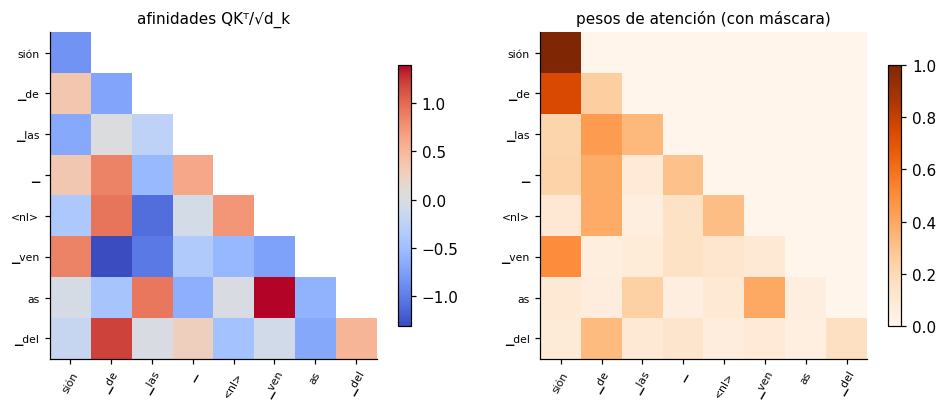

In [10]:
torch.manual_seed(SEED)
d_k = 16
W_Q, W_K, W_V = (nn.Linear(d, d_k, bias=False) for _ in range(3))
with torch.no_grad():
    Q, K, Vv = W_Q(h0[0]), W_K(h0[0]), W_V(h0[0])     # (T, d_k) cada una
    S = Q @ K.T / math.sqrt(d_k)                      # afinidades escaladas (T, T)
    T_ = S.size(0)
    M = torch.triu(torch.full((T_, T_), float("-inf")), diagonal=1)
    A = torch.softmax(S + M, dim=-1)                  # cada fila suma 1
    salida = A @ Vv                                   # (T, d_k)
    ref = F.scaled_dot_product_attention(Q[None], K[None], Vv[None], is_causal=True)[0]
print("filas de A suman:", A.sum(-1).numpy().round(4))
print("¿coincide con PyTorch?", torch.allclose(salida, ref, atol=1e-6))

piezas = [sp.id_to_piece(i) for i in x_demo.tolist()]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, Mx, tit in ((axs[0], S, "afinidades QKᵀ/√d_k"), (axs[1], A, "pesos de atención (con máscara)")):
    im = ax.imshow(Mx.numpy() if Mx is A else (S + M).numpy(), cmap="Oranges" if Mx is A else "coolwarm")
    ax.set_xticks(range(T_)); ax.set_xticklabels(piezas, rotation=60, fontsize=7)
    ax.set_yticks(range(T_)); ax.set_yticklabels(piezas, fontsize=7)
    ax.set_title(tit); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

**¿Por qué dividir entre $\sqrt{d_k}$?** Si las componentes de $q$ y $k$ son independientes con media 0 y varianza 1, el producto punto $q\cdot k = \sum_{i=1}^{d_k} q_i k_i$ es una suma de $d_k$ términos con varianza 1 cada uno, así que su varianza es $d_k$. Con $d_k = 64$ la desviación estándar ya es 8: el softmax recibe números enormes, se satura en un solo token y sus gradientes casi desaparecen. Dividir entre $\sqrt{d_k}$ regresa la varianza a 1. Comprobémoslo con números aleatorios.

In [11]:
for dk in (4, 16, 64, 256):
    q, k = torch.randn(20000, dk), torch.randn(20000, dk)
    pp = (q * k).sum(-1)
    esc = pp / math.sqrt(dk)
    p_max = torch.softmax(torch.randn(1000, 10, dk) @ torch.randn(1000, dk, 1), 1).max(1).values.mean()
    p_max_esc = torch.softmax(torch.randn(1000, 10, dk) @ torch.randn(1000, dk, 1) / math.sqrt(dk), 1).max(1).values.mean()
    print(f"d_k={dk:4d} | var(q·k)={pp.var():7.2f} | var(q·k/√d_k)={esc.var():.2f} | "
          f"prob. máxima del softmax sin escalar={p_max:.2f}, escalado={p_max_esc:.2f}")

d_k=   4 | var(q·k)=   4.14 | var(q·k/√d_k)=1.03 | prob. máxima del softmax sin escalar=0.49, escalado=0.31
d_k=  16 | var(q·k)=  15.64 | var(q·k/√d_k)=0.98 | prob. máxima del softmax sin escalar=0.72, escalado=0.32


d_k=  64 | var(q·k)=  63.53 | var(q·k/√d_k)=0.99 | prob. máxima del softmax sin escalar=0.86, escalado=0.32


d_k= 256 | var(q·k)= 255.32 | var(q·k/√d_k)=1.00 | prob. máxima del softmax sin escalar=0.93, escalado=0.32


## 5. Multi-cabeza y el bloque transformer

Una sola cabeza produce un único patrón de atención. Con $H$ cabezas, cada una con su propio $W_Q, W_K, W_V$ de dimensión $d_k = d/H$, el modelo puede atender a la vez a cosas distintas (el sujeto, la palabra anterior, el nombre propio que abrió la frase). Sus salidas se concatenan y se mezclan con una proyección $W_O$:

$$\operatorname{MHA}(H) = [\text{cabeza}_1;\dots;\text{cabeza}_H]\,W_O .$$

El **bloque** agrega una red de dos capas aplicada a cada posición por separado (FFN, con expansión $4d$ y activación GELU), normalización por capa (LayerNorm) y conexiones residuales. Usamos la variante *pre-LN* de GPT-2:

$$x \leftarrow x + \operatorname{MHA}(\operatorname{LN}(x)),\qquad x \leftarrow x + \operatorname{FFN}(\operatorname{LN}(x)).$$

Las clases siguientes son idénticas a las del script largo, así que podremos cargar su checkpoint.

In [12]:
class AtencionCausal(nn.Module):
    def __init__(self, d, H, T_max, p):
        super().__init__()
        self.qkv = nn.Linear(d, 3 * d)          # W_Q, W_K, W_V de todas las cabezas en una sola matriz
        self.proy = nn.Linear(d, d)             # W_O
        self.H, self.p = H, p
        self.drop_res = nn.Dropout(p)
        self.register_buffer("mascara", torch.tril(torch.ones(T_max, T_max)).bool(), persistent=False)

    def forward(self, x, devolver_atencion=False):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        d_k = C // self.H
        q, k, v = (t.view(B, T, self.H, d_k).transpose(1, 2) for t in (q, k, v))   # (B, H, T, d_k)
        if devolver_atencion:
            s = (q @ k.transpose(-2, -1)) / math.sqrt(d_k)
            a = F.softmax(s.masked_fill(~self.mascara[:T, :T], float("-inf")), dim=-1)
            y = a @ v
        else:
            a = None
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=self.p if self.training else 0.0)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                           # concatenar cabezas
        return self.drop_res(self.proy(y)), a


class FFN(nn.Module):
    def __init__(self, d, p):
        super().__init__()
        self.sube, self.baja, self.drop = nn.Linear(d, 4 * d), nn.Linear(4 * d, d), nn.Dropout(p)

    def forward(self, x):
        return self.drop(self.baja(F.gelu(self.sube(x), approximate="tanh")))


class Bloque(nn.Module):
    def __init__(self, d, H, T_max, p):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.atn, self.ffn = AtencionCausal(d, H, T_max, p), FFN(d, p)

    def forward(self, x, devolver_atencion=False):
        h, a = self.atn(self.ln1(x), devolver_atencion)
        x = x + h
        return x + self.ffn(self.ln2(x)), a


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, block_size=256, n_layer=6, n_head=6, n_embd=384, dropout=0.2):
        super().__init__()
        self.block_size = block_size
        self.wte, self.wpe = nn.Embedding(vocab_size, n_embd), nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.bloques = nn.ModuleList([Bloque(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.cabeza = nn.Linear(n_embd, vocab_size, bias=False)
        self.cabeza.weight = self.wte.weight    # pesos atados: la misma tabla lee y escribe tokens
        self.apply(self._init)
        for n, p in self.named_parameters():
            if n.endswith(("proy.weight", "baja.weight")):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, objetivos=None, devolver_atencion=False):
        B, T = idx.shape
        x = self.drop(self.wte(idx) + self.wpe(torch.arange(T, device=idx.device)))
        atenciones = []
        for b in self.bloques:
            x, a = b(x, devolver_atencion)
            atenciones.append(a)
        logits = self.cabeza(self.ln_f(x))
        perdida = None if objetivos is None else F.cross_entropy(logits.view(-1, logits.size(-1)), objetivos.view(-1))
        return logits, perdida, atenciones


modelo = MiniGPT(V).to(DEVICE)
total = sum(p.numel() for p in modelo.parameters())
print(f"parámetros: {total:,} ({total / 1e6:.2f} M)")
for nombre, mod in [("embeddings de token (atados con la salida)", modelo.wte), ("embeddings de posición", modelo.wpe),
                    ("un bloque", modelo.bloques[0]), ("  atención de un bloque", modelo.bloques[0].atn),
                    ("  FFN de un bloque", modelo.bloques[0].ffn)]:
    print(f"{nombre:45s} {sum(p.numel() for p in mod.parameters()):>10,}")

parámetros: 12,281,856 (12.28 M)
embeddings de token (atados con la salida)     1,536,000
embeddings de posición                            98,304
un bloque                                      1,774,464
  atención de un bloque                          591,360
  FFN de un bloque                             1,181,568


Antes de entrenar, la pérdida debe rondar $\ln V$: si el modelo no sabe nada, reparte la probabilidad casi uniforme entre los $V$ tokens y la entropía cruzada es $-\ln(1/V) = \ln V$. Es una buena prueba de que todo está bien conectado.

In [13]:
def lote(datos, B, T, gen):
    i = torch.randint(len(datos) - T - 1, (B,), generator=gen)
    x = torch.stack([datos[j:j + T] for j in i])
    y = torch.stack([datos[j + 1:j + T + 1] for j in i])
    return x.to(DEVICE), y.to(DEVICE)


gen = torch.Generator().manual_seed(SEED)
xb, yb = lote(datos_tr, 8, 256, gen)
with torch.no_grad():
    _, p0, _ = modelo(xb, yb)
print(f"pérdida inicial = {p0.item():.3f} | ln V = {math.log(V):.3f}")

pérdida inicial = 8.376 | ln V = 8.294


## 6. Entrenamiento

La pérdida es la **entropía cruzada** promedio sobre todas las posiciones del lote:

$$\mathcal{L} = -\frac{1}{BT}\sum_{b,t}\log p_\theta\big(y_{b,t}\mid x_{b,\le t}\big),\qquad \text{perplejidad} = e^{\mathcal{L}} .$$

La perplejidad se lee como "¿entre cuántos tokens duda el modelo en promedio?". Usamos AdamW con decaimiento de pesos desacoplado, una tasa de aprendizaje que sube linealmente durante el calentamiento y luego baja como un coseno, y recorte de la norma del gradiente a 1 para evitar saltos. En modo rápido entrenamos unos cuantos cientos de pasos.

In [14]:
def tasa(paso, calentamiento, total, lr_max, lr_min):
    if paso < calentamiento:
        return lr_max * (paso + 1) / calentamiento
    avance = min(1.0, (paso - calentamiento) / max(1, total - calentamiento))
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * avance))


@torch.no_grad()
def evaluar(modelo, iters=20, B=32, T=256):
    modelo.eval()
    g = torch.Generator().manual_seed(1234)
    res = {}
    for nombre, d in (("train", datos_tr), ("val", datos_va)):
        res[nombre] = float(np.mean([modelo(*lote(d, B, T, g))[1].item() for _ in range(iters)]))
    modelo.train()
    return res


PASOS = (1200 if DEVICE.type == "cuda" else 60) if RAPIDO else 6000
CAL, LR, B, T = min(200, PASOS // 5), 6e-4, 32, 256
decay = [p for p in modelo.parameters() if p.dim() >= 2]
sin_decay = [p for p in modelo.parameters() if p.dim() < 2]
opt = torch.optim.AdamW([{"params": decay, "weight_decay": 0.1}, {"params": sin_decay, "weight_decay": 0.0}],
                        lr=LR, betas=(0.9, 0.95))
amp = torch.autocast("cuda", dtype=torch.bfloat16) if DEVICE.type == "cuda" else torch.autocast("cpu", enabled=False)

hist = {"paso": [], "train": [], "lr": [], "ev_paso": [], "ev_train": [], "ev_val": []}
t0 = time.time()
modelo.train()
for paso in range(PASOS + 1):
    if paso % max(1, PASOS // 6) == 0:
        with amp:
            ev = evaluar(modelo, iters=10)
        hist["ev_paso"].append(paso); hist["ev_train"].append(ev["train"]); hist["ev_val"].append(ev["val"])
        print(f"paso {paso:5d} | train {ev['train']:.3f} | val {ev['val']:.3f} | ppl {math.exp(ev['val']):7.1f} | {time.time() - t0:5.0f} s")
    if paso == PASOS:
        break
    lr = tasa(paso, CAL, PASOS, LR, LR / 10)
    for g_ in opt.param_groups:
        g_["lr"] = lr
    xb, yb = lote(datos_tr, B, T, gen)
    with amp:
        _, perdida, _ = modelo(xb, yb)
    opt.zero_grad(set_to_none=True)
    perdida.backward()
    torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
    opt.step()
    hist["paso"].append(paso); hist["train"].append(perdida.item()); hist["lr"].append(lr)

paso     0 | train 8.372 | val 8.374 | ppl  4334.5 |     0 s


paso   200 | train 4.447 | val 4.462 | ppl    86.6 |    11 s


paso   400 | train 4.072 | val 4.157 | ppl    63.9 |    22 s


paso   600 | train 3.807 | val 3.934 | ppl    51.1 |    32 s


paso   800 | train 3.640 | val 3.815 | ppl    45.4 |    43 s


paso  1000 | train 3.541 | val 3.741 | ppl    42.2 |    54 s


paso  1200 | train 3.490 | val 3.705 | ppl    40.7 |    65 s


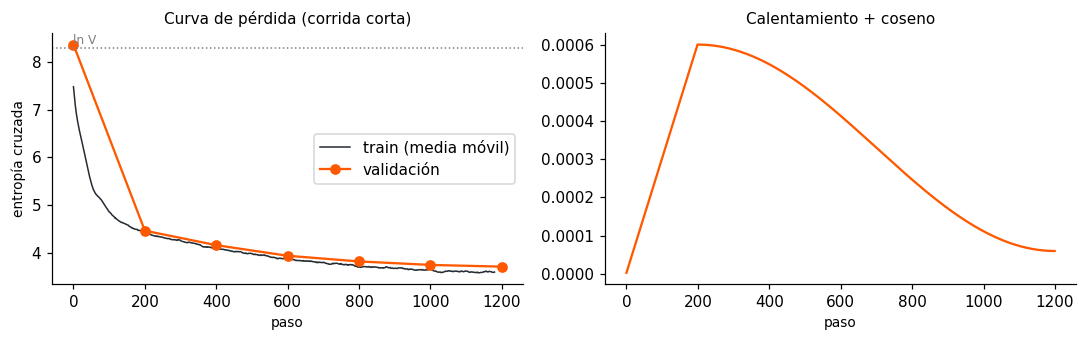

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
suave = np.convolve(hist["train"], np.ones(20) / 20, mode="valid")
axs[0].plot(hist["paso"][:len(suave)], suave, color=PIZARRA, lw=1, label="train (media móvil)")
axs[0].plot(hist["ev_paso"], hist["ev_val"], "o-", color=NARANJA, label="validación")
axs[0].axhline(math.log(V), ls=":", color="gray", lw=1); axs[0].text(0, math.log(V) + 0.1, "ln V", fontsize=8, color="gray")
axs[0].set_xlabel("paso"); axs[0].set_ylabel("entropía cruzada"); axs[0].legend(); axs[0].set_title("Curva de pérdida (corrida corta)")
axs[1].plot(hist["paso"], hist["lr"], color=NARANJA); axs[1].set_xlabel("paso"); axs[1].set_title("Calentamiento + coseno")
plt.tight_layout(); plt.show()

### La corrida larga

`scripts/train_minigpt_teresa.py` entrenó el mismo modelo durante miles de pasos, evaluando cada 250 y guardando el checkpoint con la menor pérdida de validación. Si sus resultados existen, los cargamos. En la curva se ve el fenómeno que hay que vigilar con un corpus pequeño: llega un punto en que la pérdida de entrenamiento sigue bajando mientras la de validación se estanca o sube. Ahí el modelo empieza a memorizar capítulos en lugar de aprender el idioma de la telenovela.

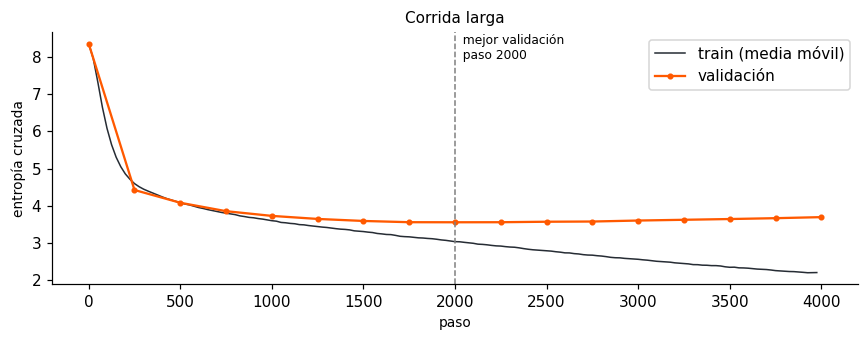

parámetros 12,281,856 | 4000 pasos en 9.5 min en NVIDIA GeForce RTX 3070 Laptop GPU
mejor val 3.557 -> perplejidad 35.0
checkpoint largo cargado (paso 2000 )


{'train': 2.802467942237854, 'val': 3.549078869819641}


In [16]:
res_json = ROOT / "data" / "processed" / "minigpt_teresa.json"
ck_path = RUN / "mejor.pt"
largo = json.loads(res_json.read_text(encoding="utf-8")) if res_json.exists() else None
if largo:
    h = largo["historia"]; m = largo["meta"]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.plot(h["paso"], h["train"], color=PIZARRA, lw=1, label="train (media móvil)")
    ax.plot(h["eval_paso"], h["eval_val"], "o-", ms=3, color=NARANJA, label="validación")
    ax.axvline(m["mejor_paso"], ls="--", color="gray", lw=1)
    ax.text(m["mejor_paso"], max(h["eval_val"]) * 0.95, f"  mejor validación\n  paso {m['mejor_paso']}", fontsize=8)
    ax.set_xlabel("paso"); ax.set_ylabel("entropía cruzada"); ax.legend(); ax.set_title("Corrida larga")
    plt.tight_layout(); plt.show()
    print(f"parámetros {m['parametros']:,} | {m['pasos']} pasos en {m['minutos']} min en {m['gpu']}")
    print(f"mejor val {m['mejor_val']:.3f} -> perplejidad {m['mejor_ppl']:.1f}")
if ck_path.exists():
    ck = torch.load(ck_path, map_location=DEVICE, weights_only=True)
    modelo.load_state_dict(ck["modelo"])
    print("checkpoint largo cargado (paso", ck["paso"], ")")
else:
    print("No hay checkpoint largo; seguimos con el modelo de la corrida corta.")
modelo.eval()
with amp:
    print(evaluar(modelo, iters=20))

## 7. Generación: temperatura, top-k y top-p

El modelo entrega **logits** $z_1,\dots,z_V$ para el siguiente token. Para convertirlos en un texto hay que elegir uno, y ahí entran tres perillas:

- **Temperatura** $\tau$: $p_i = \dfrac{e^{z_i/\tau}}{\sum_j e^{z_j/\tau}}$. Con $\tau<1$ la distribución se afila (más conservador); con $\tau>1$ se aplana (más creativo y más errático). Con $\tau\to 0$ es la búsqueda voraz: siempre el más probable.
- **Top-k**: se conservan solo los $k$ tokens más probables y se renormaliza.
- **Top-p** (núcleo): se conserva el conjunto más pequeño de tokens cuya probabilidad acumulada alcanza $p$; su tamaño se adapta a la incertidumbre del modelo.

Veamos la distribución real que el modelo asigna después de un prefijo.

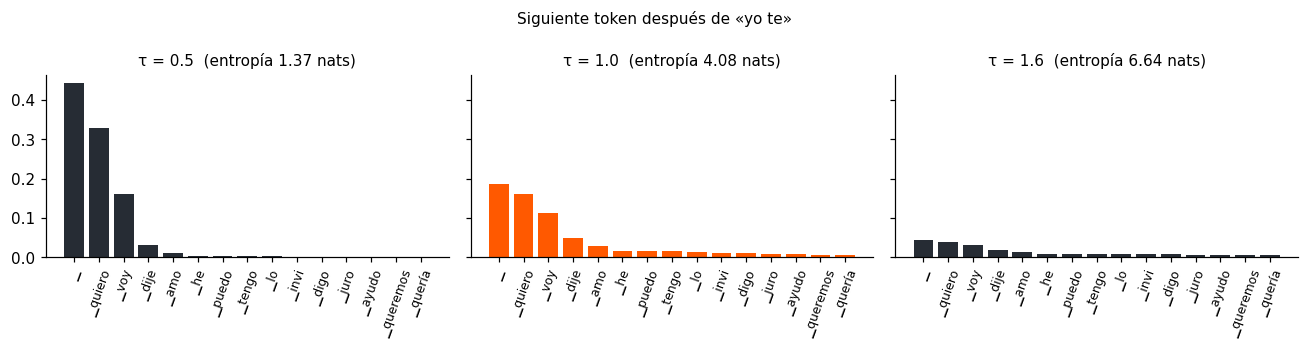

In [17]:
def siguiente(prefijo):
    ids = torch.tensor([codificar(prefijo)], device=DEVICE)
    with torch.no_grad():
        return modelo(ids)[0][0, -1].float().cpu()


prefijo = "yo te"
z = siguiente(prefijo)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, tau in zip(axs, (0.5, 1.0, 1.6)):
    p = torch.softmax(z / tau, -1)
    top = torch.topk(p, 15)
    ax.bar(range(15), top.values.numpy(), color=NARANJA if tau == 1.0 else PIZARRA)
    ax.set_xticks(range(15)); ax.set_xticklabels([sp.id_to_piece(i) for i in top.indices.tolist()], rotation=70, fontsize=8)
    H = -(p * torch.log(p + 1e-12)).sum().item()
    ax.set_title(f"τ = {tau}  (entropía {H:.2f} nats)")
fig.suptitle(f"Siguiente token después de «{prefijo}»", fontsize=10)
plt.tight_layout(); plt.show()

In [18]:
@torch.no_grad()
def generar(prefijo, n=80, temperatura=0.8, top_k=None, top_p=None, semilla=SEED):
    g = torch.Generator().manual_seed(semilla)
    idx = torch.tensor([codificar(prefijo)], device=DEVICE)
    for _ in range(n):
        z = modelo(idx[:, -modelo.block_size:])[0][0, -1].float()
        if temperatura == 0:                               # voraz
            sig = int(z.argmax())
        else:
            z = z / temperatura
            if top_k:
                kth = torch.topk(z, top_k).values[-1]
                z[z < kth] = float("-inf")
            p = torch.softmax(z, -1)
            if top_p:
                orden, indices = torch.sort(p, descending=True)
                fuera = (orden.cumsum(0) - orden) > top_p      # fuera del núcleo
                orden[fuera] = 0
                p = torch.zeros_like(p).scatter(0, indices, orden)
                p = p / p.sum()
            sig = int(torch.multinomial(p.cpu(), 1, generator=g))
        idx = torch.cat([idx, torch.tensor([[sig]], device=DEVICE)], dim=1)
    return decodificar(idx[0].tolist())


for nombre, kw in [("voraz (τ = 0)", dict(temperatura=0)),
                   ("τ = 0.8, top-k = 50", dict(temperatura=0.8, top_k=50)),
                   ("τ = 0.9, top-p = 0.9", dict(temperatura=0.9, top_p=0.9)),
                   ("τ = 1.5 sin recorte", dict(temperatura=1.5))]:
    print(f"=== {nombre} ===")
    print(generar("Teresa, eres una", **kw).replace("\n", " / "), "\n")

=== voraz (τ = 0) ===
Teresa, eres una amiga de / Teresa. Sí, sí, sí, sí. / Bueno, sí, sí, sí, sí, sí, sí, sí, sí, sí, sí, sí. / ¿Qué? ¿Qué? ¿Qué? ¿Qué? ¿Qué? ¿Qué? ¿Qué? / ¿Cómo? ¿Qué? ¿Qué? ¿Qué? ¿Qué? 

=== τ = 0.8, top-k = 50 ===


Teresa, eres una gran mujer / pero nunca va a tener dudas con lo que / quiero es que tengas de verdad. / Pues si ya no puedo hacer esto, / porque ya no podemos seguir / entre nosotros desde hace años, / pero tú y yo no, / Teresa, porque yo ya no voy a / seguir adelante, pero no me interesa. / Por favor, 

=== τ = 0.9, top-p = 0.9 ===
Teresa, eres una / Estoy de una mujer como yo, nunca más. / Yo sé que es un gran padre en cambio, / Arturo. A ver, quién viene a tomar / al papá de quiró, ni a cambio, ni / haberte copado, pero ni quiero que hablemos / de ti. Si ya que no te haces / Teresa, al menos que tengas  

=== τ = 1.5 sin recorte ===


Teresa, eres una gran mujer extra panal amor Éleres / un mensa andarlísivolver sus empresas comprenderíamos / que yo contigo si ya cambió todo iba a / pagar al fin al papáque Ivemño complejer, cuando menos me das estoy / convencido a Teresa estaban casada y resp quisieras Arturo se fue una / aferida buscar que hiciera al com todas /  



Observa los extremos. La búsqueda voraz entra en bucles («sí, sí, sí, sí», «¿Qué? ¿Qué? ¿Qué?») porque siempre toma el camino más probable. Con temperatura alta el texto se vuelve sopa de sílabas. El punto medio, con top-k o top-p, produce frases con sabor a telenovela: reclamos, juramentos, nombres de los personajes. Ese estilo salió por sí solo de minimizar la entropía cruzada sobre los diálogos.

In [19]:
if largo:
    print("Cómo aprendió a hablar el modelo largo (mismo prefijo y misma semilla en cada checkpoint):\n")
    for mu in largo["muestras"]:
        etiqueta = mu.get("etiqueta", "")
        print(f"--- paso {mu['paso']} {etiqueta} ---")
        print(mu["texto"][:260].replace("\n", " / "), "\n")

Cómo aprendió a hablar el modelo largo (mismo prefijo y misma semilla en cada checkpoint):

--- paso 0  ---
Teresa, eres una urgecre33 iglesia desadiós mereces mamita perdónrate Una gustó dime piensotorio senci Está papni empecé habpoco perdiste tiempualidad ruego dime Creí asunto vuelvocosos recuerda Ella ton edad desgraciado año añojate Tr intenté hizogda pues dij 

--- paso 50  ---
Teresa, eres una /  / ¿ amor / que / lo / mal / ? / que / que, de / no / a / que / que / que que que / que me / me tú estoy / que / que que porque / de / me / no a que / que / no /  / ver que / . / que  

--- paso 150  ---
Teresa, eres una / ya no, no, no, / lo que tú te / es que te veo en la que estás de mí. / ¿Y no, por qué. / Mariano, qué te / que me lo que me das y yo te / a mí, porque yo te dije que se me dije que no te quería / que / Teresa. / a ver, pero no. / Pero si 

--- paso 300  ---
Teresa, eres una / ya no, no sabía qué / que lo que tú te / es que te hagas en que yo solo si / no / a tener a h

## 8. ¿Qué mira cada cabeza?

Pidamos al modelo entrenado sus pesos de atención para una frase dramática. Cada panel es una cabeza de la última capa: la fila es la posición que pregunta y la columna la posición que responde. La máscara causal deja vacío el triángulo superior. Suelen aparecer cabezas que miran al token anterior (una diagonal justo debajo de la principal), cabezas que se quedan en el primer token (una columna oscura a la izquierda, un "lugar de descanso" cuando no hay nada útil que mirar) y cabezas que conectan palabras relacionadas.

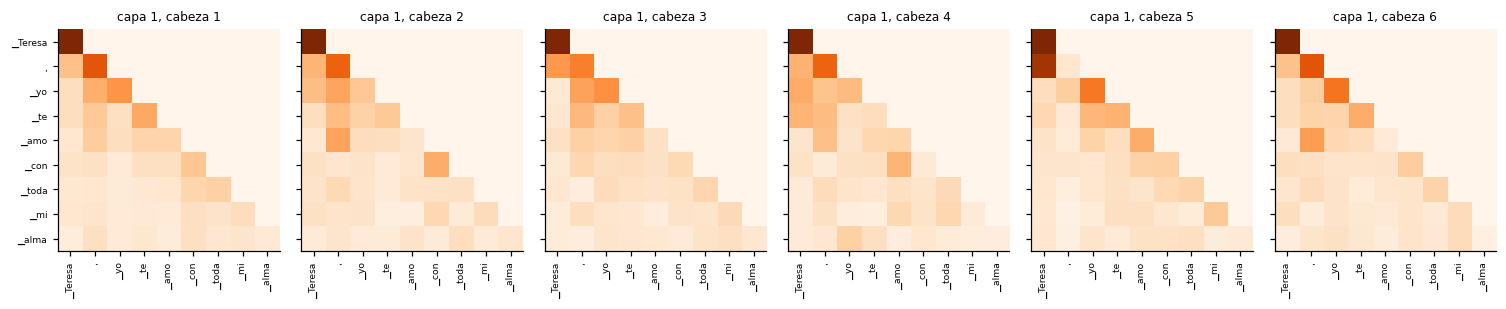

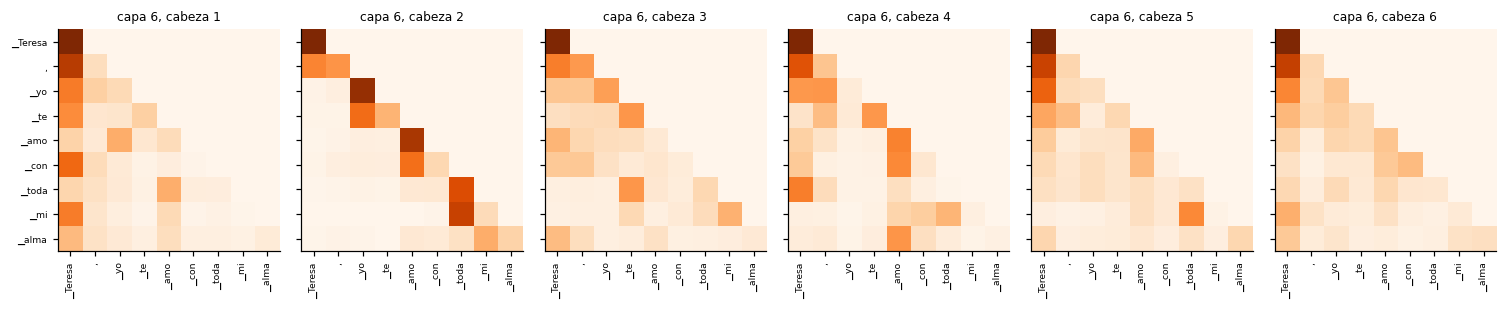

In [20]:
frase = "Teresa, yo te amo con toda mi alma"
ids = codificar(frase)
piezas = [sp.id_to_piece(i) for i in ids]
with torch.no_grad():
    _, _, atn = modelo(torch.tensor([ids], device=DEVICE), devolver_atencion=True)
for capa in (0, len(atn) - 1):
    A = atn[capa][0].float().cpu().numpy()
    fig, axs = plt.subplots(1, A.shape[0], figsize=(2.3 * A.shape[0], 2.6))
    for h_, ax in enumerate(axs):
        ax.imshow(A[h_], cmap="Oranges", vmin=0, vmax=1)
        ax.set_xticks(range(len(piezas))); ax.set_xticklabels(piezas, rotation=90, fontsize=6)
        ax.set_yticks(range(len(piezas))); ax.set_yticklabels(piezas if h_ == 0 else [], fontsize=6)
        ax.set_title(f"capa {capa + 1}, cabeza {h_ + 1}", fontsize=8)
    plt.tight_layout(); plt.show()

## Ejercicios

1. Cambia el tamaño del vocabulario BPE a 1000 y a 8000. ¿Cuántos caracteres por token obtienes en cada caso? ¿Cómo cambia la pérdida inicial $\ln V$ y por qué no se pueden comparar directamente las perplejidades entre vocabularios distintos?
2. Quita la división entre $\sqrt{d_k}$ en `AtencionCausal` y entrena la corrida corta. Compara la curva de pérdida con la original.
3. Elimina la máscara causal (usa `is_causal=False`). La pérdida de entrenamiento baja muchísimo. ¿Por qué ese modelo es inútil para generar?
4. Con el prefijo `"yo te"`, calcula a mano el tamaño del núcleo para $p = 0.5$ y $p = 0.9$ usando la distribución de la sección 7.
5. Duplica el dropout a 0.4 en la corrida larga. ¿Se retrasa el punto en que la validación deja de mejorar?
6. Cuenta los parámetros de un bloque en función de $d$ y verifica que da $12d^2 + 13d$. ¿Qué fracción del modelo está en los embeddings?